## Deep Learning Model Optimization (LSTM, GRU and CNN-LSTM)

### Import libraries

In [141]:
# Data handling
import pandas as pd
import numpy as np

# Visualization
import matplotlib.pyplot as plt
import seaborn as sns

# Hyperparameter search and evaluation
from sklearn.model_selection import ParameterSampler, ParameterGrid
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

# PyTorch
import torch
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import TensorDataset, DataLoader

# Utilities
import copy
import time
import random
import joblib
from pathlib import Path

### Set random seed and device

In [142]:
# Fixed seed so every trial starts from the same conditions
SEED = 42

def set_seed(seed=SEED):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)

set_seed()

# Select available computing device
device = torch.device(
    "mps" if torch.backends.mps.is_available()
    else "cpu"
)

print("PyTorch version:", torch.__version__)
print("Selected device:", device)

PyTorch version: 2.15.0
Selected device: mps


### Load the dataset

In [143]:
# Define project paths
data_path = Path("../data/processed/energy_data_features.csv")
models_dir = Path("../models")
reports_dir = Path("../reports")

# Load the dataset
df = pd.read_csv(data_path, parse_dates=["date"])

# Cyclical time features, created the same way as in model development
# (they are not stored in the CSV, but they are part of feature_columns)
df["hour_sin"] = np.sin(2 * np.pi * df["hour"] / 24)
df["hour_cos"] = np.cos(2 * np.pi * df["hour"] / 24)
df["day_of_week_sin"] = np.sin(2 * np.pi * df["day_of_week"] / 7)
df["day_of_week_cos"] = np.cos(2 * np.pi * df["day_of_week"] / 7)

# Load the feature columns used during model development
feature_columns = joblib.load(models_dir / "feature_columns.pkl")

# Select input features and target variable
X = df[feature_columns]
y = df["Appliances"]

print("Dataset shape:", df.shape)
print("Input features shape:", X.shape)
print("Target shape:", y.shape)

Dataset shape: (19717, 44)
Input features shape: (19717, 37)
Target shape: (19717,)


### Chronological data splitting and scaling
Same 70% / 10% / 20% split as model development. The saved scalers were fitted on the training data only.

In [144]:
# Calculate split indexes
train_size = int(len(df) * 0.70)
val_size = int(len(df) * 0.80)

# Split input features
X_train = X.iloc[:train_size]
X_val = X.iloc[train_size:val_size]
X_test = X.iloc[val_size:]

# Split target values
y_train = y.iloc[:train_size]
y_val = y.iloc[train_size:val_size]
y_test = y.iloc[val_size:]

# Load the saved scalers
X_scaler = joblib.load(models_dir / "X_scaler.pkl")
y_scaler = joblib.load(models_dir / "y_scaler.pkl")

# Scale input features
X_train_scaled = X_scaler.transform(X_train)
X_val_scaled = X_scaler.transform(X_val)
X_test_scaled = X_scaler.transform(X_test)

# Scale target values
y_train_scaled = y_scaler.transform(y_train.to_numpy().reshape(-1, 1))
y_val_scaled = y_scaler.transform(y_val.to_numpy().reshape(-1, 1))
y_test_scaled = y_scaler.transform(y_test.to_numpy().reshape(-1, 1))

print("Training data:", X_train_scaled.shape)
print("Validation data:", X_val_scaled.shape)
print("Testing data:", X_test_scaled.shape)

Training data: (13801, 37)
Validation data: (1972, 37)
Testing data: (3944, 37)


### Prepare time series sequences

In [145]:
# Number of time steps in each window (current row + 5 previous rows)
sequence_length = 6

# Combine the scaled datasets in chronological order
X_all_scaled = np.concatenate([X_train_scaled, X_val_scaled, X_test_scaled])
y_all_scaled = np.concatenate([
    y_train_scaled.ravel(),
    y_val_scaled.ravel(),
    y_test_scaled.ravel()
])

# Function to create time series sequences
def create_sequences(X_data, y_data, start, end, sequence_length):

    X_sequences = []
    y_sequences = []

    for i in range(max(start, sequence_length - 1), end):

        # Take the window ending at the current time step
        # (row i only holds past consumption through lag/rolling features, so it is safe to use)
        X_sequences.append(X_data[i - sequence_length + 1:i + 1])

        # Predict the target at the current time step
        y_sequences.append(y_data[i])

    return np.array(X_sequences), np.array(y_sequences)


# Create training, validation and testing sequences
X_train_seq, y_train_seq = create_sequences(X_all_scaled, y_all_scaled, 0, train_size, sequence_length)
X_val_seq, y_val_seq = create_sequences(X_all_scaled, y_all_scaled, train_size, val_size, sequence_length)
X_test_seq, y_test_seq = create_sequences(X_all_scaled, y_all_scaled, val_size, len(df), sequence_length)

print("Training sequences:", X_train_seq.shape)
print("Validation sequences:", X_val_seq.shape)
print("Testing sequences:", X_test_seq.shape)

Training sequences: (13796, 6, 37)
Validation sequences: (1972, 6, 37)
Testing sequences: (3944, 6, 37)


### Create PyTorch datasets and DataLoaders

In [146]:
# Create datasets from PyTorch tensors
train_dataset = TensorDataset(
    torch.tensor(X_train_seq, dtype=torch.float32),
    torch.tensor(y_train_seq, dtype=torch.float32)
)

val_dataset = TensorDataset(
    torch.tensor(X_val_seq, dtype=torch.float32),
    torch.tensor(y_val_seq, dtype=torch.float32)
)

test_dataset = TensorDataset(
    torch.tensor(X_test_seq, dtype=torch.float32),
    torch.tensor(y_test_seq, dtype=torch.float32)
)

# Batch size is a hyperparameter, so the training loaders are created per trial
def create_data_loaders(batch_size):

    train_loader = DataLoader(train_dataset, batch_size=batch_size, shuffle=True)
    val_loader = DataLoader(val_dataset, batch_size=batch_size, shuffle=False)

    return train_loader, val_loader


# Fixed loaders for evaluation (batch size does not affect predictions)
val_eval_loader = DataLoader(val_dataset, batch_size=256, shuffle=False)
test_loader = DataLoader(test_dataset, batch_size=256, shuffle=False)

input_size = X_train_seq.shape[2]

print("Input size:", input_size)
print("Testing batches:", len(test_loader))

Input size: 37
Testing batches: 16


### Define configurable model architectures

In [147]:
class LSTMModel(nn.Module):

    def __init__(self, input_size, hidden_size, dropout_rate,
                 num_layers=1, dense_units=32):

        super(LSTMModel, self).__init__()

        # LSTM layers (PyTorch only applies dropout between stacked layers)
        self.lstm = nn.LSTM(
            input_size=input_size,
            hidden_size=hidden_size,
            num_layers=num_layers,
            dropout=dropout_rate if num_layers > 1 else 0.0,
            batch_first=True
        )

        # Dropout layer
        self.dropout = nn.Dropout(dropout_rate)

        # Fully connected hidden layer
        self.fc1 = nn.Linear(hidden_size, dense_units)

        # ReLU activation
        self.relu = nn.ReLU()

        # Output layer
        self.fc2 = nn.Linear(dense_units, 1)

    def forward(self, x):

        # Pass input through LSTM
        lstm_output, (hidden_state, cell_state) = self.lstm(x)

        # Select the final time step output and apply dropout
        output = self.dropout(lstm_output[:, -1, :])

        # Dense layer with ReLU activation
        output = self.relu(self.fc1(output))

        # Generate prediction
        output = self.fc2(output)

        return output.squeeze(-1)

In [148]:
class GRUModel(nn.Module):

    def __init__(self, input_size, hidden_size, dropout_rate,
                 num_layers=1, dense_units=32):

        super(GRUModel, self).__init__()

        # GRU layers (PyTorch only applies dropout between stacked layers)
        self.gru = nn.GRU(
            input_size=input_size,
            hidden_size=hidden_size,
            num_layers=num_layers,
            dropout=dropout_rate if num_layers > 1 else 0.0,
            batch_first=True
        )

        # Dropout layer
        self.dropout = nn.Dropout(dropout_rate)

        # Fully connected hidden layer
        self.fc1 = nn.Linear(hidden_size, dense_units)

        # ReLU activation
        self.relu = nn.ReLU()

        # Output layer
        self.fc2 = nn.Linear(dense_units, 1)

    def forward(self, x):

        # Pass input through GRU
        gru_output, hidden_state = self.gru(x)

        # Select the final time step output and apply dropout
        output = self.dropout(gru_output[:, -1, :])

        # Dense layer with ReLU activation
        output = self.relu(self.fc1(output))

        # Generate prediction
        output = self.fc2(output)

        return output.squeeze(-1)

In [149]:
class CNNLSTMModel(nn.Module):

    def __init__(self, input_size, hidden_size, dropout_rate,
                 conv_filters=64, num_layers=1, dense_units=32):

        super(CNNLSTMModel, self).__init__()

        # CNN layer
        self.conv1 = nn.Conv1d(
            in_channels=input_size,
            out_channels=conv_filters,
            kernel_size=2
        )

        # ReLU activation
        self.relu = nn.ReLU()

        # LSTM layers (PyTorch only applies dropout between stacked layers)
        self.lstm = nn.LSTM(
            input_size=conv_filters,
            hidden_size=hidden_size,
            num_layers=num_layers,
            dropout=dropout_rate if num_layers > 1 else 0.0,
            batch_first=True
        )

        # Dropout
        self.dropout = nn.Dropout(dropout_rate)

        # Dense layer
        self.fc1 = nn.Linear(hidden_size, dense_units)

        # Output layer
        self.fc2 = nn.Linear(dense_units, 1)

    def forward(self, x):

        # Change input shape for CNN: (batch, features, time_steps)
        x = x.transpose(1, 2)

        # Extract local patterns using CNN
        x = self.relu(self.conv1(x))

        # Change shape back for LSTM: (batch, time_steps, features)
        x = x.transpose(1, 2)

        # Pass CNN output into LSTM
        lstm_output, (hidden_state, cell_state) = self.lstm(x)

        # Get final time step and apply dropout
        output = self.dropout(lstm_output[:, -1, :])

        # Dense layer with ReLU activation
        output = self.relu(self.fc1(output))

        # Prediction
        output = self.fc2(output)

        return output.squeeze(-1)

### Build a model from its hyperparameters

In [150]:
model_names = ["LSTM", "GRU", "CNN-LSTM"]

def build_model(model_name, params):

    common_params = {
        "input_size": input_size,
        "hidden_size": params["hidden_size"],
        "dropout_rate": params["dropout_rate"],
        "num_layers": params["num_layers"],
        "dense_units": params["dense_units"]
    }

    if model_name == "LSTM":
        model = LSTMModel(**common_params)

    elif model_name == "GRU":
        model = GRUModel(**common_params)

    else:
        model = CNNLSTMModel(conv_filters=params["conv_filters"], **common_params)

    return model.to(device)

### Evaluation helper functions

In [151]:
# Generate predictions (scaled) for a DataLoader
def predict(model, data_loader):

    model.eval()

    predictions = []

    with torch.no_grad():

        for batch_X, batch_y in data_loader:

            batch_X = batch_X.to(device)

            predictions.extend(model(batch_X).cpu().numpy())

    return np.array(predictions)


# Calculate MAE, RMSE and R2 in the original Wh scale
def calculate_metrics(actual, predictions):

    return {
        "MAE": mean_absolute_error(actual, predictions),
        "RMSE": np.sqrt(mean_squared_error(actual, predictions)),
        "R2 Score": r2_score(actual, predictions)
    }


def evaluate_model(model, data_loader, y_true_scaled):

    predictions = y_scaler.inverse_transform(
        predict(model, data_loader).reshape(-1, 1)
    ).ravel()

    actual = y_scaler.inverse_transform(
        y_true_scaled.reshape(-1, 1)
    ).ravel()

    return calculate_metrics(actual, predictions), actual, predictions

### Performance before optimization

In [152]:
# Hyperparameters used in model_development_and_training.ipynb
def get_baseline_params(model_name):

    params = {
        "learning_rate": 0.001,
        "batch_size": 64,
        "num_epochs": 50,
        "num_layers": 1,
        "hidden_size": 64,
        "dense_units": 32,
        "dropout_rate": 0.2
    }

    if model_name == "CNN-LSTM":
        params["conv_filters"] = 64

    return params


baseline_files = {
    "LSTM": "lstm_model.pth",
    "GRU": "gru_model.pth",
    "CNN-LSTM": "cnn_lstm_model.pth"
}

baseline_models = {}
baseline_val_metrics = {}
baseline_test_metrics = {}
baseline_test_predictions = {}

for model_name in model_names:

    # Load the saved baseline model
    checkpoint = torch.load(models_dir / baseline_files[model_name], map_location=device)

    model = build_model(model_name, get_baseline_params(model_name))
    model.load_state_dict(checkpoint["model_state_dict"])

    baseline_models[model_name] = model

    # Evaluate on validation and test data
    baseline_val_metrics[model_name], _, _ = evaluate_model(model, val_eval_loader, y_val_seq)
    baseline_test_metrics[model_name], test_actual, baseline_test_predictions[model_name] = evaluate_model(
        model, test_loader, y_test_seq
    )

baseline_results = pd.concat({
    "Validation": pd.DataFrame(baseline_val_metrics).T,
    "Test": pd.DataFrame(baseline_test_metrics).T
}, axis=1)

print("Baseline models (before optimization)")
display(baseline_results.round(4))

Baseline models (before optimization)


Validation                       Test                  
                MAE     RMSE R2 Score      MAE     RMSE R2 Score
LSTM        23.7191  59.0042   0.6026  24.1327  57.5786   0.5957
GRU         23.8904  59.4637   0.5964  25.7992  58.5674   0.5817
CNN-LSTM    24.0308  58.6928   0.6068  24.8708  59.6526   0.5661

### Early stopping

In [153]:
class EarlyStopping:

    def __init__(self, patience=7, min_delta=1e-4):

        self.patience = patience
        self.min_delta = min_delta

        self.best_loss = float("inf")
        self.best_weights = None
        self.best_epoch = 0

        self.counter = 0
        self.stop = False

    def step(self, val_loss, model, epoch):

        if val_loss < self.best_loss - self.min_delta:

            # Validation loss improved: save the weights
            self.best_loss = val_loss
            self.best_weights = copy.deepcopy(model.state_dict())
            self.best_epoch = epoch
            self.counter = 0

        else:

            # No improvement
            self.counter += 1

            if self.counter >= self.patience:
                self.stop = True

### Training function

In [154]:
# Same training settings as model_development_and_training.ipynb
weight_decay = 1e-4
max_grad_norm = 1.0
lr_scheduler_patience = 3


def train_model(model_name, params, patience=7, verbose=False):

    # Same starting conditions for every configuration
    set_seed()

    train_loader, val_loader = create_data_loaders(params["batch_size"])

    model = build_model(model_name, params)

    # Huber loss: less dominated by the rare consumption spikes than MSE
    criterion = nn.HuberLoss()
    optimizer = optim.Adam(model.parameters(), lr=params["learning_rate"], weight_decay=weight_decay)

    # Halve the learning rate when validation loss stops improving
    scheduler = optim.lr_scheduler.ReduceLROnPlateau(optimizer, factor=0.5, patience=lr_scheduler_patience)

    early_stopping = EarlyStopping(patience=patience)

    train_losses = []
    val_losses = []

    for epoch in range(1, params["num_epochs"] + 1):

        #training phase

        model.train()

        running_train_loss = 0.0

        for batch_X, batch_y in train_loader:

            batch_X = batch_X.to(device)
            batch_y = batch_y.to(device)

            optimizer.zero_grad()

            loss = criterion(model(batch_X), batch_y)

            loss.backward()

            # Clip gradients to keep LSTM/GRU training stable
            nn.utils.clip_grad_norm_(model.parameters(), max_norm=max_grad_norm)

            optimizer.step()

            running_train_loss += loss.item() * batch_X.size(0)

        epoch_train_loss = running_train_loss / len(train_loader.dataset)

        #validation phase

        model.eval()

        running_val_loss = 0.0

        with torch.no_grad():

            for batch_X, batch_y in val_loader:

                batch_X = batch_X.to(device)
                batch_y = batch_y.to(device)

                loss = criterion(model(batch_X), batch_y)

                running_val_loss += loss.item() * batch_X.size(0)

        epoch_val_loss = running_val_loss / len(val_loader.dataset)

        # Adjust learning rate based on validation loss
        scheduler.step(epoch_val_loss)

        train_losses.append(epoch_train_loss)
        val_losses.append(epoch_val_loss)

        if verbose:
            print(
                f"Epoch [{epoch}/{params['num_epochs']}] "
                f"Training Loss: {epoch_train_loss:.4f} "
                f"Validation Loss: {epoch_val_loss:.4f}"
            )

        #Early stopping

        early_stopping.step(epoch_val_loss, model, epoch)

        if early_stopping.stop:

            if verbose:
                print(f"Early stopping triggered at epoch {epoch}!")
            break

    # Restore the best model weights
    model.load_state_dict(early_stopping.best_weights)

    history = {
        "train_losses": train_losses,
        "val_losses": val_losses,
        "best_epoch": early_stopping.best_epoch,
        "stopped_epoch": epoch,
        "best_val_loss": early_stopping.best_loss
    }

    return model, history

## 1. Hyperparameter Tuning (Random Search)

In [155]:
# Hyperparameter search space shared by all models
common_grid = {
    "learning_rate": [0.0003, 0.0005, 0.001, 0.003],
    "batch_size": [32, 64, 128],
    "num_epochs": [30, 50],
    "num_layers": [1, 2],
    "hidden_size": [32, 64, 128],
    "dense_units": [16, 32, 64],
    "dropout_rate": [0.2]
}

param_grids = {
    "LSTM": common_grid,
    "GRU": common_grid,
    "CNN-LSTM": {**common_grid, "conv_filters": [32, 64]}
}

# Number of random configurations to try per model
n_trials = 20

for model_name in model_names:
    print(f"{model_name}: {len(ParameterGrid(param_grids[model_name]))} combinations, {n_trials} trials")

LSTM: 432 combinations, 20 trials
GRU: 432 combinations, 20 trials
CNN-LSTM: 864 combinations, 20 trials


### Run Random Search for every model

In [156]:
tuning_results = {}
best_params = {}

for model_name in model_names:

    print({model_name})

    param_samples = list(ParameterSampler(param_grids[model_name], n_iter=n_trials, random_state=SEED))

    results = []

    for trial, params in enumerate(param_samples, start=1):

        start_time = time.time()

        model, history = train_model(model_name, params)

        val_metrics, _, _ = evaluate_model(model, val_eval_loader, y_val_seq)

        results.append({
            "Model": model_name,
            "Trial": trial,
            **params,
            "Best Epoch": history["best_epoch"],
            "Stopped Epoch": history["stopped_epoch"],
            "Val Loss": history["best_val_loss"],
            "Val MAE": val_metrics["MAE"],
            "Val RMSE": val_metrics["RMSE"],
            "Val R2": val_metrics["R2 Score"],
            "Time (s)": time.time() - start_time
        })

        print(
            f"Trial {trial:2d}/{n_trials} | "
            f"lr={params['learning_rate']}, batch={params['batch_size']}, "
            f"layers={params['num_layers']}, hidden={params['hidden_size']}, "
            f"dense={params['dense_units']}"
            + (f", filters={params['conv_filters']}" if "conv_filters" in params else "")
            + f" | Val Loss: {history['best_val_loss']:.4f} | "
            f"Val MAE: {val_metrics['MAE']:.2f} | "
            f"stopped at epoch {history['stopped_epoch']}"
        )

    results = pd.DataFrame(results).sort_values("Val Loss").reset_index(drop=True)

    tuning_results[model_name] = results

    # Best hyperparameters = lowest validation loss
    best_trial = int(results.loc[0, "Trial"])
    best_params[model_name] = param_samples[best_trial - 1]

{'LSTM'}


Trial  1/20 | lr=0.001, batch=128, layers=1, hidden=128, dense=64 | Val Loss: 0.0942 | Val MAE: 23.97 | stopped at epoch 21
Trial  2/20 | lr=0.001, batch=32, layers=2, hidden=64, dense=32 | Val Loss: 0.0929 | Val MAE: 23.96 | stopped at epoch 14
Trial  3/20 | lr=0.0005, batch=64, layers=1, hidden=128, dense=16 | Val Loss: 0.0948 | Val MAE: 24.91 | stopped at epoch 20
Trial  4/20 | lr=0.003, batch=32, layers=1, hidden=64, dense=16 | Val Loss: 0.0945 | Val MAE: 24.52 | stopped at epoch 14
Trial  5/20 | lr=0.001, batch=128, layers=1, hidden=32, dense=64 | Val Loss: 0.0963 | Val MAE: 24.45 | stopped at epoch 16
Trial  6/20 | lr=0.0003, batch=64, layers=2, hidden=128, dense=64 | Val Loss: 0.0956 | Val MAE: 23.72 | stopped at epoch 18
Trial  7/20 | lr=0.003, batch=128, layers=1, hidden=64, dense=64 | Val Loss: 0.0949 | Val MAE: 23.56 | stopped at epoch 15
Trial  8/20 | lr=0.001, batch=64, layers=1, hidden=32, dense=16 | Val Loss: 0.0946 | Val MAE: 23.76 | stopped at epoch 14
Trial  9/20 | lr

### Random Search results: top 5 trials per model

In [157]:
for model_name in model_names:

    print(f"{model_name}")
    display(tuning_results[model_name].head(5).round(4))

LSTM


,Model,Trial,num_layers,num_epochs,learning_rate,hidden_size,dropout_rate,dense_units,batch_size,Best Epoch,Stopped Epoch,Val Loss,Val MAE,Val RMSE,Val R2,Time (s)
0,LSTM,2,2,50,0.0010,64,0.2,32,32,7,14,0.0929,23.9640,58.6522,0.6073,29.3426
1,LSTM,17,1,50,0.0030,128,0.2,32,128,10,17,0.0936,23.6209,59.2734,0.5990,12.4331
2,LSTM,14,1,50,0.0030,128,0.2,16,128,6,13,0.0937,24.0730,59.3239,0.5983,9.6713
3,LSTM,16,2,30,0.0030,64,0.2,16,64,13,20,0.0938,23.6722,58.7540,0.6060,22.5737
4,LSTM,12,1,50,0.0005,64,0.2,32,32,9,16,0.0938,23.6985,58.9468,0.6034,24.1120


GRU


,Model,Trial,num_layers,num_epochs,learning_rate,hidden_size,dropout_rate,dense_units,batch_size,Best Epoch,Stopped Epoch,Val Loss,Val MAE,Val RMSE,Val R2,Time (s)
0,GRU,4,1,50,0.0030,64,0.2,16,32,14,21,0.0920,23.6399,58.6612,0.6072,50.4026
1,GRU,17,1,50,0.0030,128,0.2,32,128,11,18,0.0923,23.3790,58.9801,0.6029,12.9957
2,GRU,8,1,50,0.0010,32,0.2,16,64,10,17,0.0925,23.7206,58.2576,0.6126,26.7899
3,GRU,15,2,50,0.0005,128,0.2,16,32,21,28,0.0926,23.8369,58.4494,0.6100,118.0212
4,GRU,10,1,30,0.0005,32,0.2,16,64,17,24,0.0927,23.9325,58.4818,0.6096,37.7009


CNN-LSTM


,Model,Trial,num_layers,num_epochs,learning_rate,hidden_size,dropout_rate,dense_units,conv_filters,batch_size,Best Epoch,Stopped Epoch,Val Loss,Val MAE,Val RMSE,Val R2,Time (s)
0,CNN-LSTM,8,1,50,0.0010,32,0.2,16,32,64,9,16,0.0922,23.5813,57.9290,0.6170,13.8382
1,CNN-LSTM,5,2,50,0.0005,64,0.2,16,32,32,18,25,0.0924,24.3873,57.6989,0.6200,226.9003
2,CNN-LSTM,17,2,50,0.0003,64,0.2,32,32,32,16,23,0.0925,23.8094,58.1972,0.6134,54.8099
3,CNN-LSTM,6,2,50,0.0010,32,0.2,16,32,64,11,18,0.0925,23.9957,58.1832,0.6136,24.1786
4,CNN-LSTM,4,2,30,0.0005,64,0.2,16,32,64,12,19,0.0927,23.7492,58.3976,0.6107,21.1973


#### Best hyperparameters found for each model

In [158]:
# Convert values to text so integers are not shown as floats
best_params_table = pd.DataFrame({
    model_name: {name: str(value) for name, value in best_params[model_name].items()}
    for model_name in model_names
}).fillna("-")

display(best_params_table)

,LSTM,GRU,CNN-LSTM
num_layers,2,1,1
num_epochs,50,50,50
learning_rate,0.001,0.003,0.001
hidden_size,64,64,32
dropout_rate,0.2,0.2,0.2
dense_units,32,16,16
batch_size,32,32,64
conv_filters,-,-,32


#### Effect of each hyperparameter on validation loss

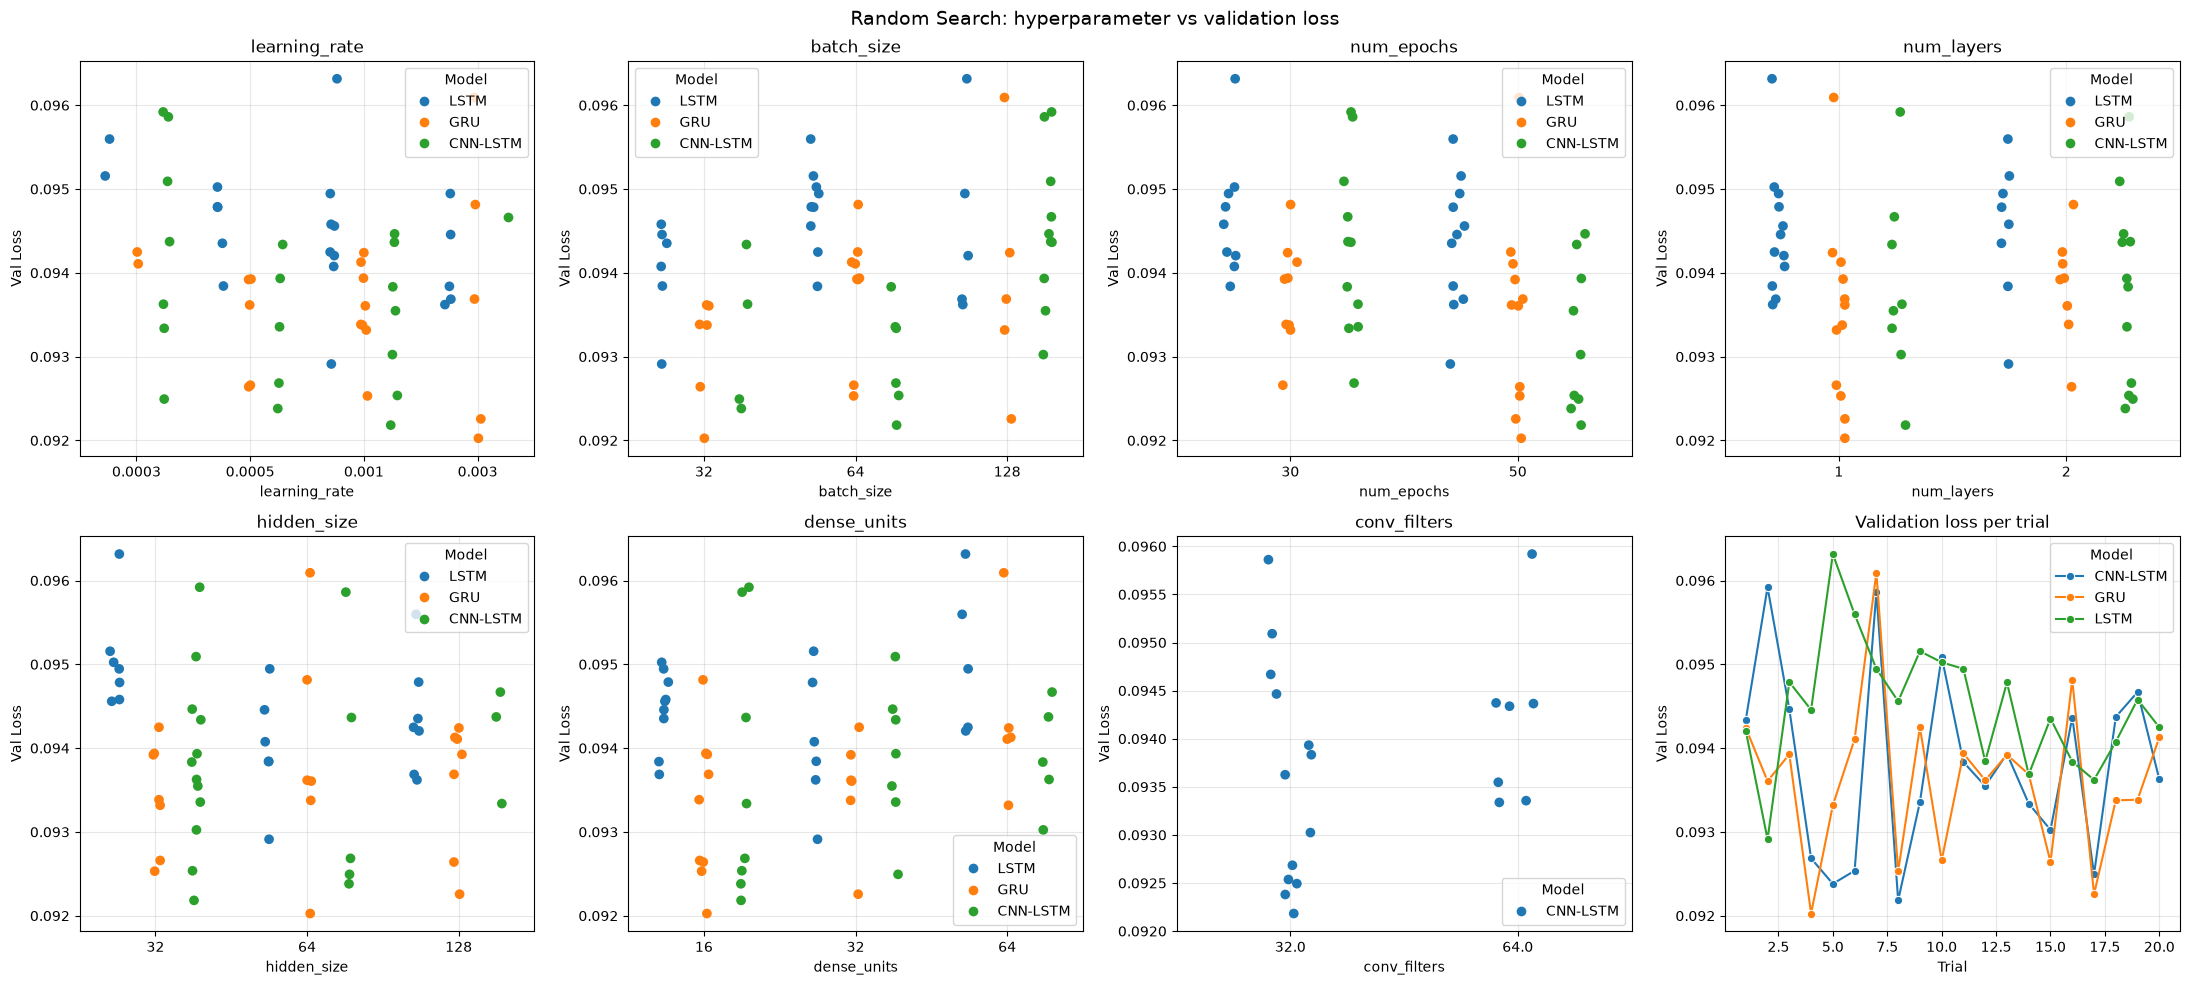

In [159]:
all_tuning_results = pd.concat(tuning_results.values(), ignore_index=True)

tuned_parameters = [
    "learning_rate", "batch_size", "num_epochs", "num_layers",
    "hidden_size", "dense_units", "conv_filters"
]

fig, axes = plt.subplots(2, 4, figsize=(22, 10))
axes = axes.ravel()

for ax, parameter in zip(axes, tuned_parameters):

    sns.stripplot(
        data=all_tuning_results.dropna(subset=[parameter]),
        x=parameter,
        y="Val Loss",
        hue="Model",
        dodge=True,
        size=7,
        ax=ax
    )

    ax.set_title(parameter)
    ax.grid(True, alpha=0.3)

# Best validation loss per trial for each model
sns.lineplot(
    data=all_tuning_results.sort_values("Trial"),
    x="Trial",
    y="Val Loss",
    hue="Model",
    marker="o",
    ax=axes[-1]
)
axes[-1].set_title("Validation loss per trial")
axes[-1].grid(True, alpha=0.3)

plt.suptitle("Random Search: hyperparameter vs validation loss", fontsize=14)
plt.tight_layout()
plt.show()

## 2. Regularization Techniques (Dropout)

In [160]:
dropout_rates = [0.0, 0.1, 0.2, 0.3, 0.4, 0.5]

dropout_results = []
dropout_models = {}
dropout_histories = {}

for model_name in model_names:

    print({model_name})

    for rate in dropout_rates:

        params = {**best_params[model_name], "dropout_rate": rate}

        model, history = train_model(model_name, params)

        val_metrics, _, _ = evaluate_model(model, val_eval_loader, y_val_seq)

        dropout_models[(model_name, rate)] = model
        dropout_histories[(model_name, rate)] = history

        dropout_results.append({
            "Model": model_name,
            "Dropout Rate": rate,
            "Best Epoch": history["best_epoch"],
            "Stopped Epoch": history["stopped_epoch"],
            "Train Loss (best epoch)": history["train_losses"][history["best_epoch"] - 1],
            "Val Loss": history["best_val_loss"],
            "Val MAE": val_metrics["MAE"],
            "Val RMSE": val_metrics["RMSE"],
            "Val R2": val_metrics["R2 Score"]
        })

        print(
            f"Dropout {rate:.1f} | "
            f"Val Loss: {history['best_val_loss']:.4f} | "
            f"Val MAE: {val_metrics['MAE']:.2f} | "
            f"Val R2: {val_metrics['R2 Score']:.4f}"
        )

dropout_results = pd.DataFrame(dropout_results)

display(dropout_results.round(4))

{'LSTM'}
Dropout 0.0 | Val Loss: 0.0944 | Val MAE: 24.10 | Val R2: 0.6100
Dropout 0.1 | Val Loss: 0.0934 | Val MAE: 23.74 | Val R2: 0.6007
Dropout 0.2 | Val Loss: 0.0929 | Val MAE: 23.96 | Val R2: 0.6073
Dropout 0.3 | Val Loss: 0.0929 | Val MAE: 23.79 | Val R2: 0.6049
Dropout 0.4 | Val Loss: 0.0940 | Val MAE: 23.67 | Val R2: 0.6000
Dropout 0.5 | Val Loss: 0.0941 | Val MAE: 23.65 | Val R2: 0.5974
{'GRU'}
Dropout 0.0 | Val Loss: 0.0944 | Val MAE: 24.42 | Val R2: 0.5915
Dropout 0.1 | Val Loss: 0.0929 | Val MAE: 23.66 | Val R2: 0.6110
Dropout 0.2 | Val Loss: 0.0920 | Val MAE: 23.64 | Val R2: 0.6072
Dropout 0.3 | Val Loss: 0.0934 | Val MAE: 24.08 | Val R2: 0.6036
Dropout 0.4 | Val Loss: 0.0924 | Val MAE: 23.36 | Val R2: 0.6083
Dropout 0.5 | Val Loss: 0.0931 | Val MAE: 23.40 | Val R2: 0.6050
{'CNN-LSTM'}
Dropout 0.0 | Val Loss: 0.0941 | Val MAE: 24.41 | Val R2: 0.6068
Dropout 0.1 | Val Loss: 0.0927 | Val MAE: 24.04 | Val R2: 0.6090
Dropout 0.2 | Val Loss: 0.0922 | Val MAE: 23.58 | Val R2: 0.

,Model,Dropout Rate,Best Epoch,Stopped Epoch,Train Loss (best epoch),Val Loss,Val MAE,Val RMSE,Val R2
0,LSTM,0.0,3,10,0.1236,0.0944,24.0994,58.4523,0.6100
1,LSTM,0.1,7,14,0.1192,0.0934,23.7410,59.1478,0.6007
2,LSTM,0.2,7,14,0.1225,0.0929,23.9640,58.6522,0.6073
3,LSTM,0.3,7,14,0.1244,0.0929,23.7900,58.8359,0.6049
4,LSTM,0.4,7,14,0.1289,0.0940,23.6703,59.1979,0.6000
5,LSTM,0.5,13,20,0.1223,0.0941,23.6471,59.3855,0.5974
6,GRU,0.0,11,18,0.1001,0.0944,24.4184,59.8208,0.5915
7,GRU,0.1,14,21,0.1023,0.0929,23.6612,58.3755,0.6110
8,GRU,0.2,14,21,0.1054,0.0920,23.6399,58.6612,0.6072
9,GRU,0.3,14,21,0.1197,0.0934,24.0812,58.9281,0.6036


#### Compare dropout rates

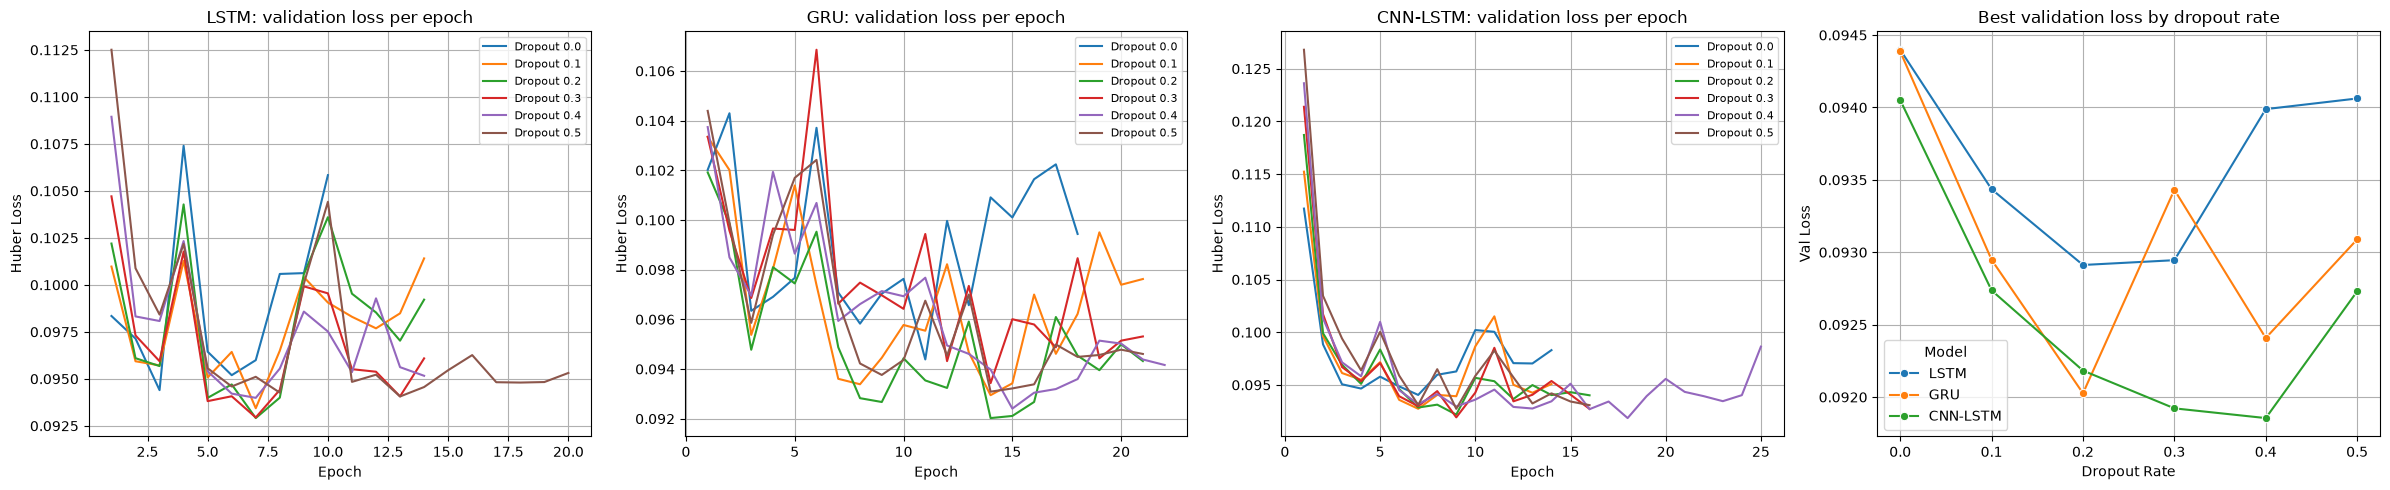

LSTM best dropout rate: 0.2
GRU best dropout rate: 0.2
CNN-LSTM best dropout rate: 0.4


In [161]:
fig, axes = plt.subplots(1, 4, figsize=(24, 5))

# Validation loss curves for each dropout rate, one plot per model
for ax, model_name in zip(axes, model_names):

    for rate in dropout_rates:

        val_losses = dropout_histories[(model_name, rate)]["val_losses"]

        ax.plot(range(1, len(val_losses) + 1), val_losses, label=f"Dropout {rate}")

    ax.set_title(f"{model_name}: validation loss per epoch")
    ax.set_xlabel("Epoch")
    ax.set_ylabel("Huber Loss")
    ax.legend(fontsize=8)
    ax.grid(True)

# Best validation loss for each dropout rate
sns.lineplot(data=dropout_results, x="Dropout Rate", y="Val Loss", hue="Model", marker="o", ax=axes[-1])
axes[-1].set_title("Best validation loss by dropout rate")
axes[-1].grid(True)

plt.tight_layout()
plt.show()

# Select the dropout rate with the lowest validation loss for each model
best_dropout = {
    model_name: float(group.loc[group["Val Loss"].idxmin(), "Dropout Rate"])
    for model_name, group in dropout_results.groupby("Model")
}

for model_name in model_names:
    print(f"{model_name} best dropout rate: {best_dropout[model_name]}")

### Final optimized models

In [162]:
optimized_params = {}
optimized_models = {}
optimized_histories = {}

for model_name in model_names:

    optimized_params[model_name] = {**best_params[model_name], "dropout_rate": best_dropout[model_name]}

    optimized_models[model_name] = dropout_models[(model_name, best_dropout[model_name])]
    optimized_histories[model_name] = dropout_histories[(model_name, best_dropout[model_name])]

    parameters = sum(p.numel() for p in optimized_models[model_name].parameters() if p.requires_grad)

    print(f"{model_name}: {parameters} trainable parameters")

LSTM: 61761 trainable parameters
GRU: 20833 trainable parameters
CNN-LSTM: 11393 trainable parameters


## 3. Early Stopping


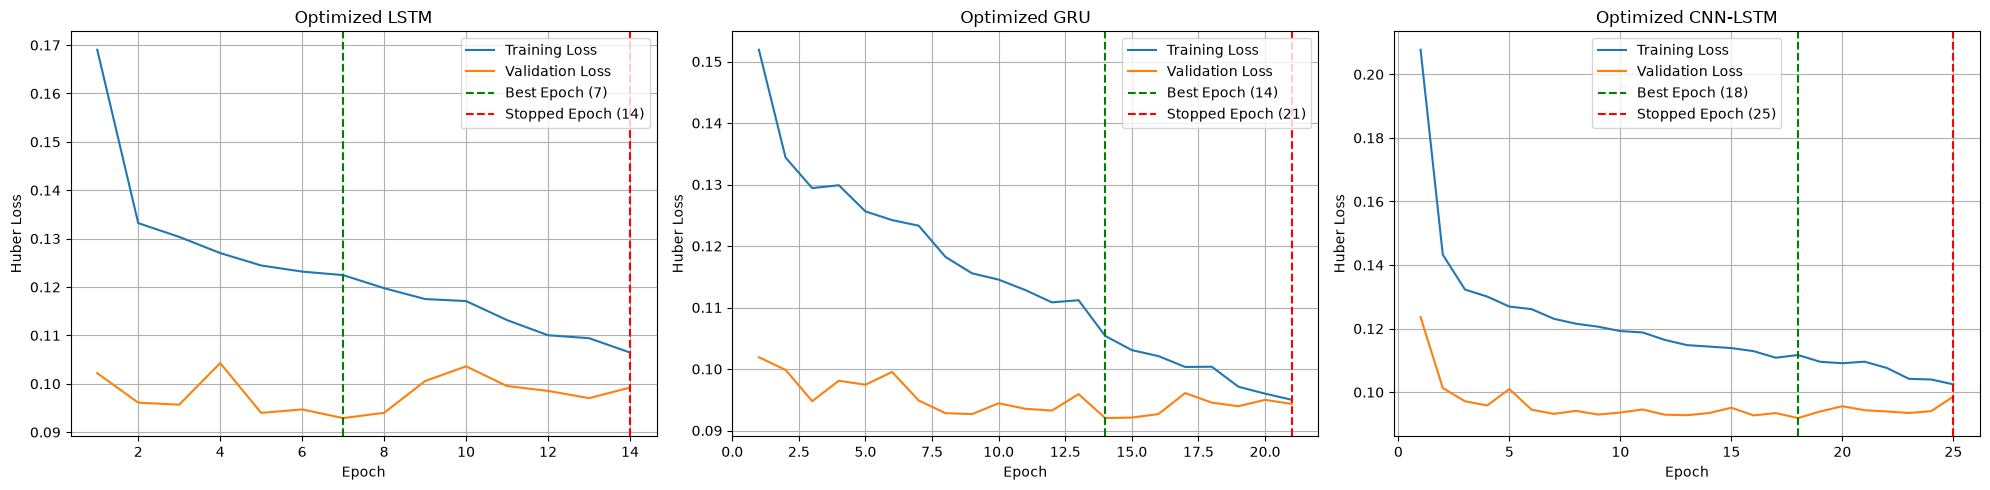

,Model,Maximum Epochs,Stopped Epoch,Best Epoch,Epochs Saved
0,LSTM,50,14,7,36
1,GRU,50,21,14,29
2,CNN-LSTM,50,25,18,25


In [163]:
fig, axes = plt.subplots(1, 3, figsize=(20, 5))

early_stopping_summary = []

for ax, model_name in zip(axes, model_names):

    history = optimized_histories[model_name]
    epochs = range(1, len(history["train_losses"]) + 1)

    ax.plot(epochs, history["train_losses"], label="Training Loss")
    ax.plot(epochs, history["val_losses"], label="Validation Loss")

    ax.axvline(x=history["best_epoch"], color="green", linestyle="--", label=f"Best Epoch ({history['best_epoch']})")
    ax.axvline(x=history["stopped_epoch"], color="red", linestyle="--", label=f"Stopped Epoch ({history['stopped_epoch']})")

    ax.set_title(f"Optimized {model_name}")
    ax.set_xlabel("Epoch")
    ax.set_ylabel("Huber Loss")
    ax.legend()
    ax.grid(True)

    early_stopping_summary.append({
        "Model": model_name,
        "Maximum Epochs": optimized_params[model_name]["num_epochs"],
        "Stopped Epoch": history["stopped_epoch"],
        "Best Epoch": history["best_epoch"],
        "Epochs Saved": optimized_params[model_name]["num_epochs"] - history["stopped_epoch"]
    })

plt.tight_layout()
plt.show()

display(pd.DataFrame(early_stopping_summary))

## 4. Model Evaluation Post Optimization

In [164]:
optimized_val_metrics = {}
optimized_test_metrics = {}
optimized_test_predictions = {}

for model_name in model_names:

    optimized_val_metrics[model_name], _, _ = evaluate_model(
        optimized_models[model_name], val_eval_loader, y_val_seq
    )

    optimized_test_metrics[model_name], _, optimized_test_predictions[model_name] = evaluate_model(
        optimized_models[model_name], test_loader, y_test_seq
    )

optimized_results = pd.concat({
    "Validation": pd.DataFrame(optimized_val_metrics).T,
    "Test": pd.DataFrame(optimized_test_metrics).T
}, axis=1)

print("Optimized models (after optimization)")
display(optimized_results.round(4))

Optimized models (after optimization)


Validation                       Test                  
                MAE     RMSE R2 Score      MAE     RMSE R2 Score
LSTM        23.9640  58.6522   0.6073  24.8423  57.9815   0.5901
GRU         23.6399  58.6612   0.6072  26.2013  58.3904   0.5843
CNN-LSTM    23.6148  57.9557   0.6166  24.6716  59.5906   0.5670

### Compare performance before and after optimization

In [165]:
comparison = []

for model_name in model_names:

    for metric in ["MAE", "RMSE", "R2 Score"]:

        before = baseline_test_metrics[model_name][metric]
        after = optimized_test_metrics[model_name][metric]

        comparison.append({
            "Model": model_name,
            "Test Metric": metric,
            "Before Optimization": before,
            "After Optimization": after,
            # Percentage change (MAE and RMSE should go down, R2 should go up)
            "Change (%)": (after - before) / abs(before) * 100,
            "Improved": after > before if metric == "R2 Score" else after < before
        })

comparison = pd.DataFrame(comparison).set_index(["Model", "Test Metric"])

display(comparison.round(4))

Before Optimization  After Optimization  Change (%)  \
Model    Test Metric                                                        
LSTM     MAE                      24.1327             24.8423      2.9401   
         RMSE                     57.5786             57.9815      0.6998   
         R2 Score                  0.5957              0.5901     -0.9531   
GRU      MAE                      25.7992             26.2013      1.5587   
         RMSE                     58.5674             58.3904     -0.3023   
         R2 Score                  0.5817              0.5843      0.4341   
CNN-LSTM MAE                      24.8708             24.6716     -0.8008   
         RMSE                     59.6526             59.5906     -0.1039   
         R2 Score                  0.5661              0.5670      0.1592   

                      Improved  
Model    Test Metric            
LSTM     MAE             False  
         RMSE            False  
         R2 Score        False  
GRU      MAE             False  
         RMSE             True  
         R2 Score         True  
CNN-LSTM MAE              True  
         RMSE             True  
         R2 Score         True

#### Hyperparameters before and after optimization

In [166]:
params_comparison = {}

for model_name in model_names:

    # Convert values to text so integers are not shown as floats
    params_comparison[(model_name, "Before")] = {
        name: str(value) for name, value in get_baseline_params(model_name).items()
    }
    params_comparison[(model_name, "After")] = {
        name: str(value) for name, value in optimized_params[model_name].items()
    }

params_comparison = pd.DataFrame(params_comparison).fillna("-")

display(params_comparison)

LSTM           GRU        CNN-LSTM       
              Before  After Before  After   Before  After
learning_rate  0.001  0.001  0.001  0.003    0.001  0.001
batch_size        64     32     64     32       64     64
num_epochs        50     50     50     50       50     50
num_layers         1      2      1      1        1      1
hidden_size       64     64     64     64       64     32
dense_units       32     32     32     16       32     16
dropout_rate     0.2    0.2    0.2    0.2      0.2    0.4
conv_filters       -      -      -      -       64     32

#### Visualize test metrics before and after optimization

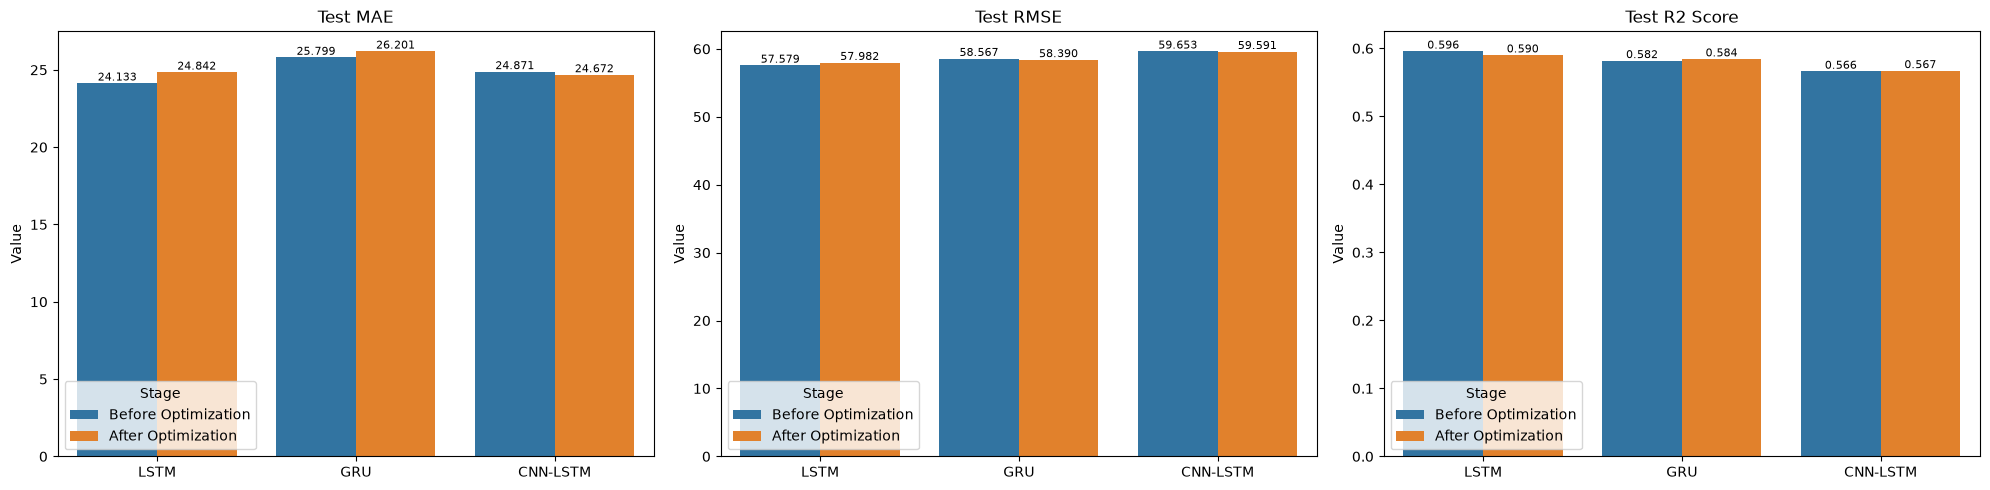

In [167]:
plot_data = comparison[["Before Optimization", "After Optimization"]].reset_index().melt(
    id_vars=["Model", "Test Metric"],
    var_name="Stage",
    value_name="Value"
)

fig, axes = plt.subplots(1, 3, figsize=(20, 5))

for ax, metric in zip(axes, ["MAE", "RMSE", "R2 Score"]):

    sns.barplot(
        data=plot_data[plot_data["Test Metric"] == metric],
        x="Model",
        y="Value",
        hue="Stage",
        ax=ax
    )

    # Show values on top of the bars
    for container in ax.containers:
        ax.bar_label(container, fmt="%.3f", fontsize=8)

    ax.set_title(f"Test {metric}")
    ax.set_xlabel("")

plt.tight_layout()
plt.show()

#### Actual vs predicted on the test set

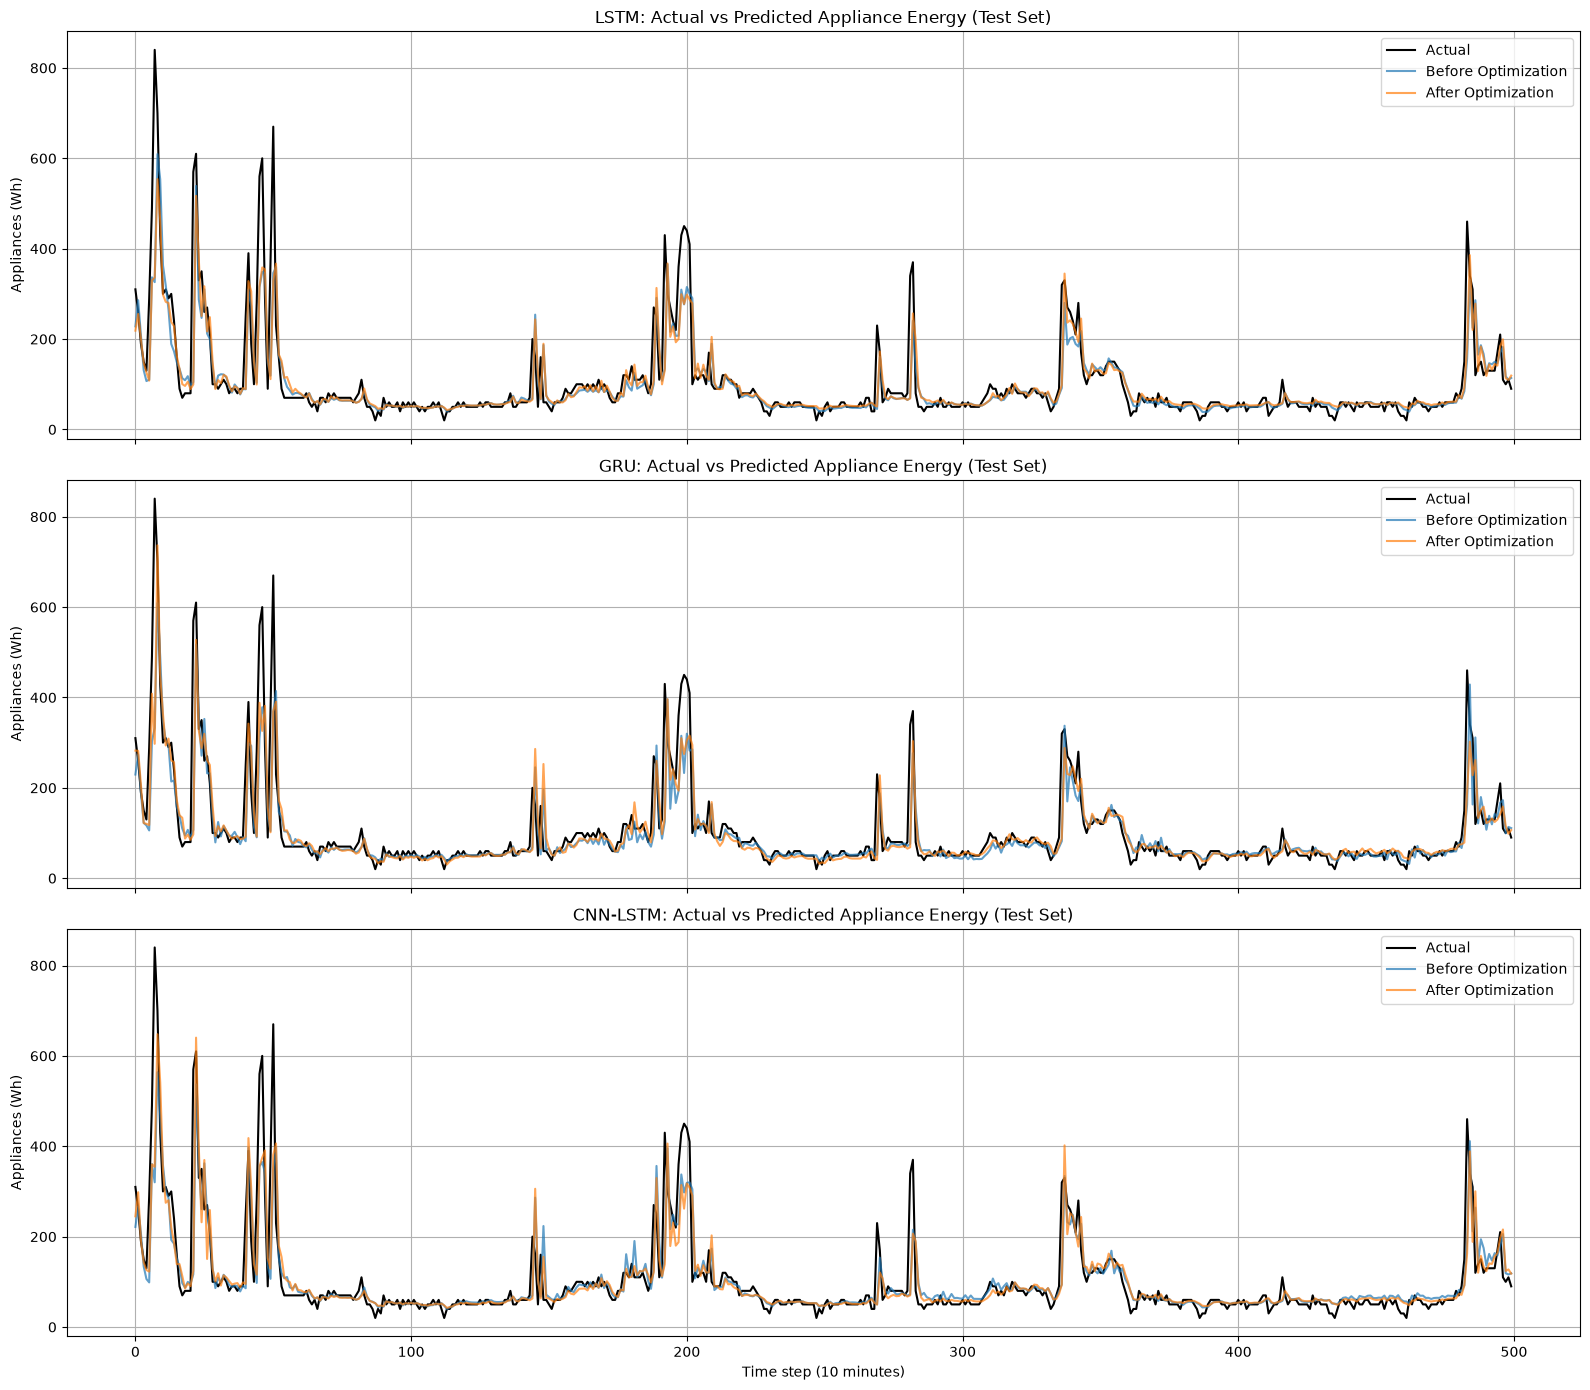

In [168]:
# Plot the first 500 test time steps (each step is 10 minutes)
n_points = 500

fig, axes = plt.subplots(3, 1, figsize=(16, 14), sharex=True)

for ax, model_name in zip(axes, model_names):

    ax.plot(test_actual[:n_points], label="Actual", color="black", linewidth=1.5)
    ax.plot(baseline_test_predictions[model_name][:n_points], label="Before Optimization", alpha=0.7)
    ax.plot(optimized_test_predictions[model_name][:n_points], label="After Optimization", alpha=0.7)

    ax.set_title(f"{model_name}: Actual vs Predicted Appliance Energy (Test Set)")
    ax.set_ylabel("Appliances (Wh)")
    ax.legend()
    ax.grid(True)

axes[-1].set_xlabel("Time step (10 minutes)")

plt.tight_layout()
plt.show()

### Final test comparison of all models

In [169]:
# Load the saved baseline models
lr_model = joblib.load(models_dir / "linear_regression.pkl")
rf_model = joblib.load(models_dir / "random_forest.pkl")

# Linear Regression was trained on scaled features, Random Forest on original features
lr_test_predictions = y_scaler.inverse_transform(
    lr_model.predict(X_test_scaled).reshape(-1, 1)
).ravel()
rf_test_predictions = rf_model.predict(X_test)

final_results = {
    "Linear Regression": calculate_metrics(y_test.to_numpy(), lr_test_predictions),
    "Random Forest": calculate_metrics(y_test.to_numpy(), rf_test_predictions)
}

for model_name in model_names:
    final_results[f"{model_name} (before)"] = baseline_test_metrics[model_name]
    final_results[f"{model_name} (optimized)"] = optimized_test_metrics[model_name]

final_results = pd.DataFrame(final_results).T.sort_values("RMSE")
final_results.index.name = "Model"

display(final_results.round(4))

,MAE,RMSE,R2 Score
Model,,,
LSTM (before),24.1327,57.5786,0.5957
LSTM (optimized),24.8423,57.9815,0.5901
GRU (optimized),26.2013,58.3904,0.5843
GRU (before),25.7992,58.5674,0.5817
CNN-LSTM (optimized),24.6716,59.5906,0.5670
CNN-LSTM (before),24.8708,59.6526,0.5661
Linear Regression,27.5256,61.0734,0.5452
Random Forest,79.1738,120.5100,-0.7709


In [170]:
from sklearn.metrics import mean_absolute_percentage_error

# Test predictions of every model (original Wh scale)
test_predictions = {
    "Linear Regression": lr_test_predictions,
    "Random Forest": rf_test_predictions
}

for model_name in model_names:
    test_predictions[f"{model_name} (before)"] = baseline_test_predictions[model_name]
    test_predictions[f"{model_name} (optimized)"] = optimized_test_predictions[model_name]

print("Minimum actual value in the test set:", round(test_actual.min(), 2), "Wh")

# Add MAPE to the final comparison table
final_results["MAPE (%)"] = [
    mean_absolute_percentage_error(test_actual, test_predictions[model]) * 100
    for model in final_results.index
]

final_results = final_results[["MAE", "RMSE", "MAPE (%)", "R2 Score"]]

display(final_results.round(4))

Minimum actual value in the test set: 20.0 Wh


,MAE,RMSE,MAPE (%),R2 Score
Model,,,,
LSTM (before),24.1327,57.5786,20.5560,0.5957
LSTM (optimized),24.8423,57.9815,22.2104,0.5901
GRU (optimized),26.2013,58.3904,25.0253,0.5843
GRU (before),25.7992,58.5674,23.8006,0.5817
CNN-LSTM (optimized),24.6716,59.5906,21.1391,0.5670
CNN-LSTM (before),24.8708,59.6526,20.6637,0.5661
Linear Regression,27.5256,61.0734,25.6203,0.5452
Random Forest,79.1738,120.5100,87.8112,-0.7709


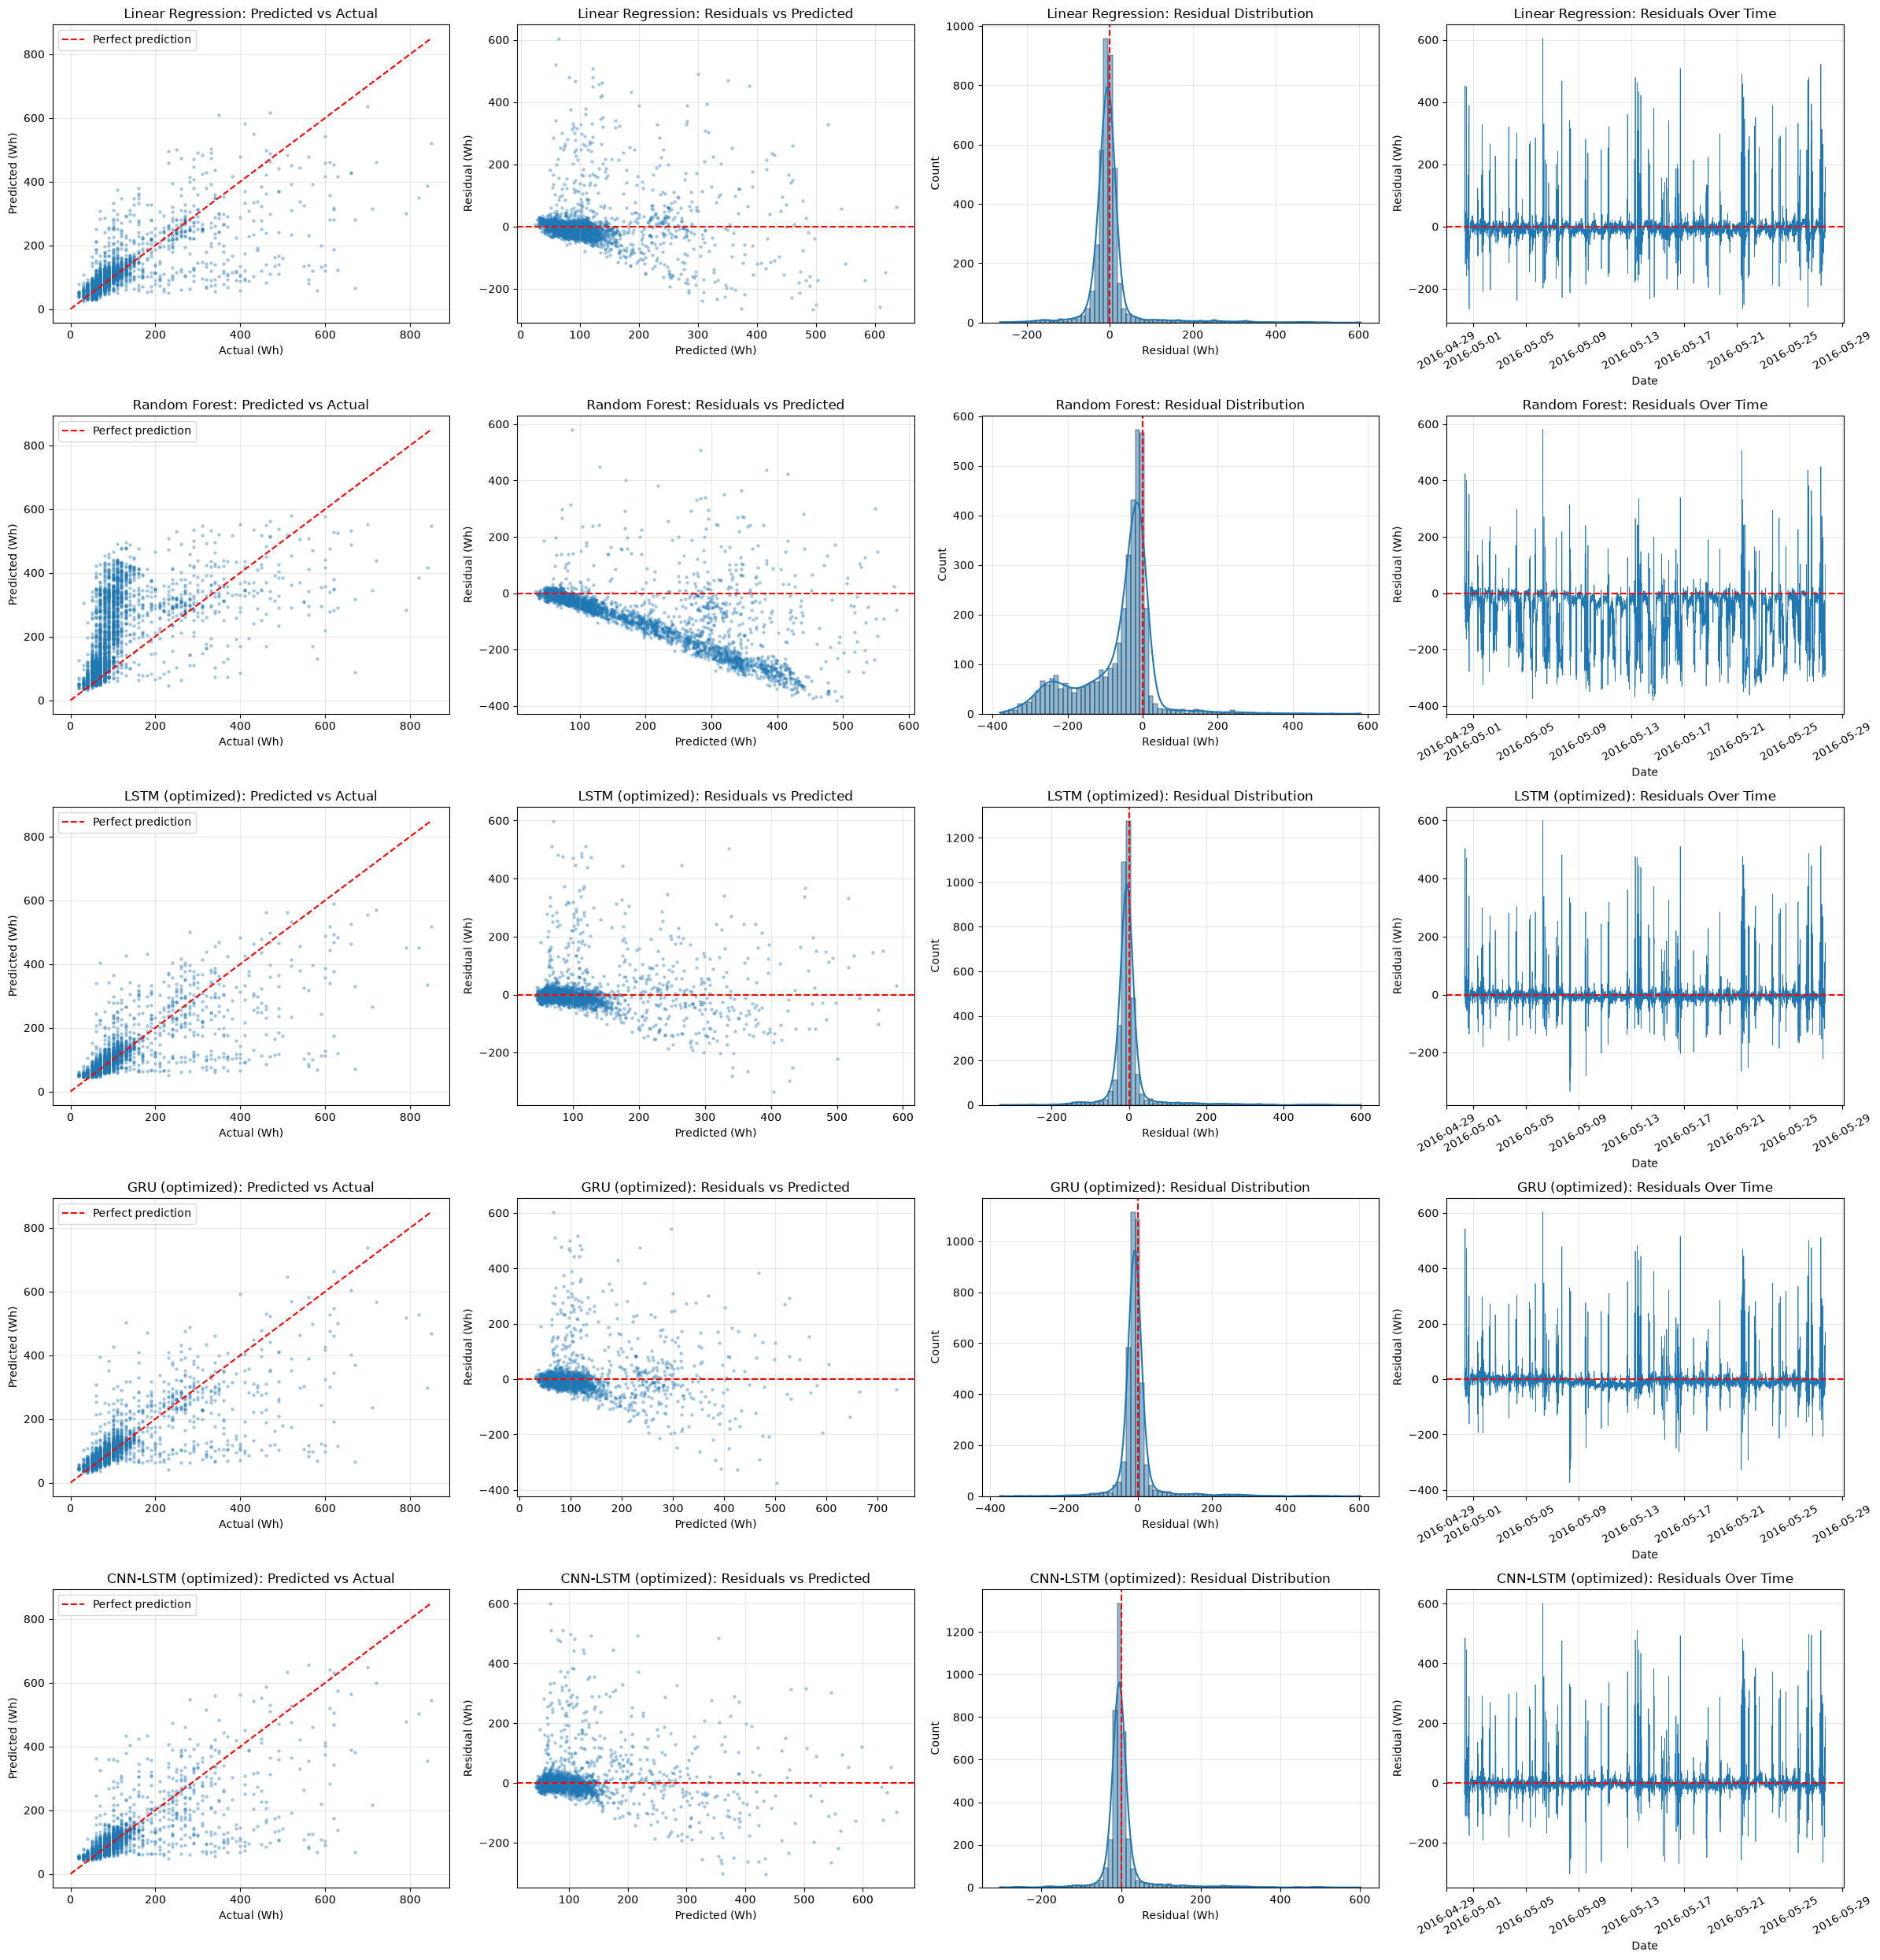

In [171]:
# Residual = actual - predicted (positive = under-prediction)
residual_models = [
    "Linear Regression",
    "Random Forest",
    "LSTM (optimized)",
    "GRU (optimized)",
    "CNN-LSTM (optimized)"
]

# Dates of the test targets (sequence targets start at the first test row)
test_dates = df["date"].iloc[val_size:].to_numpy()

fig, axes = plt.subplots(len(residual_models), 4, figsize=(24, 5 * len(residual_models)))

for row, model in zip(axes, residual_models):

    predictions = test_predictions[model]
    residuals = test_actual - predictions

    # 1. Predicted vs actual
    limit = max(test_actual.max(), predictions.max())
    row[0].scatter(test_actual, predictions, s=5, alpha=0.3)
    row[0].plot([0, limit], [0, limit], color="red", linestyle="--", label="Perfect prediction")
    row[0].set_title(f"{model}: Predicted vs Actual")
    row[0].set_xlabel("Actual (Wh)")
    row[0].set_ylabel("Predicted (Wh)")
    row[0].legend()

    # 2. Residuals vs predicted
    row[1].scatter(predictions, residuals, s=5, alpha=0.3)
    row[1].axhline(0, color="red", linestyle="--")
    row[1].set_title(f"{model}: Residuals vs Predicted")
    row[1].set_xlabel("Predicted (Wh)")
    row[1].set_ylabel("Residual (Wh)")

    # 3. Residual distribution
    sns.histplot(residuals, bins=80, kde=True, ax=row[2])
    row[2].axvline(0, color="red", linestyle="--")
    row[2].set_title(f"{model}: Residual Distribution")
    row[2].set_xlabel("Residual (Wh)")

    # 4. Residuals over time
    row[3].plot(test_dates, residuals, linewidth=0.5)
    row[3].axhline(0, color="red", linestyle="--")
    row[3].set_title(f"{model}: Residuals Over Time")
    row[3].set_xlabel("Date")
    row[3].set_ylabel("Residual (Wh)")
    row[3].tick_params(axis="x", rotation=30)

    for ax in row:
        ax.grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

#### Residual statistics

In [172]:
residual_summary = []

for model in residual_models:

    residuals = test_actual - test_predictions[model]

    residual_summary.append({
        "Model": model,
        "Mean Residual (bias)": residuals.mean(),
        "Median Residual": np.median(residuals),
        "Std Residual": residuals.std(),
        "Skewness": pd.Series(residuals).skew(),
        "Within ±25 Wh (%)": (np.abs(residuals) <= 25).mean() * 100,
        "Largest Under-prediction": residuals.max(),
        "Largest Over-prediction": residuals.min()
    })

residual_summary = pd.DataFrame(residual_summary).set_index("Model")

display(residual_summary.round(2))

,Mean Residual (bias),Median Residual,Std Residual,Skewness,Within ±25 Wh (%),Largest Under-prediction,Largest Over-prediction
Model,,,,,,,
Linear Regression,-0.14,-5.73,61.07,3.53,76.93,605.10,-265.26
Random Forest,-66.45,-31.90,100.53,-0.35,40.72,581.10,-380.20
LSTM (optimized),0.56,-5.60,57.98,3.78,80.93,599.78,-334.12
GRU (optimized),-1.46,-7.74,58.37,3.76,77.79,603.74,-373.72
CNN-LSTM (optimized),3.33,-4.02,59.50,3.65,82.18,602.33,-304.52


### Save the optimized models and results

In [173]:
model_file_names = {
    "LSTM": "lstm",
    "GRU": "gru",
    "CNN-LSTM": "cnn_lstm"
}

for model_name in model_names:

    file_name = model_file_names[model_name]

    # Save optimized model with its hyperparameters
    torch.save({
        "model_state_dict": optimized_models[model_name].state_dict(),
        "input_size": input_size,
        "sequence_length": sequence_length,
        **optimized_params[model_name]
    }, models_dir / f"{file_name}_optimized_model.pth")

    # Save tuning and dropout results
    tuning_results[model_name].to_csv(reports_dir / f"{file_name}_tuning_results.csv", index=False)
    dropout_results[dropout_results["Model"] == model_name].to_csv(
        reports_dir / f"{file_name}_dropout_results.csv", index=False
    )

# Save before/after comparison and final comparison
comparison.to_csv(reports_dir / "model_optimization_comparison.csv")
final_results.to_csv(reports_dir / "final_test_results.csv")

print("Optimized models and results saved successfully")

Optimized models and results saved successfully


### Summary

In [174]:
print("Model Optimization Summary")
print("--------------------------")

for model_name in model_names:

    history = optimized_histories[model_name]

    print(f"\n{model_name}")
    print(f"  Random Search trials: {n_trials} (out of {len(ParameterGrid(param_grids[model_name]))} combinations)")
    print(f"  Best dropout rate: {best_dropout[model_name]}")
    print(f"  Early stopping: stopped at epoch {history['stopped_epoch']}, best epoch {history['best_epoch']}")

    for metric in ["MAE", "RMSE", "R2 Score"]:
        row = comparison.loc[(model_name, metric)]
        print(
            f"  Test {metric}: {row['Before Optimization']:.4f} -> "
            f"{row['After Optimization']:.4f} ({row['Change (%)']:+.2f}%)"
        )

print(f"\nBest model on the test set (lowest RMSE): {final_results.index[0]}")

Model Optimization Summary
--------------------------

LSTM
  Random Search trials: 20 (out of 432 combinations)
  Best dropout rate: 0.2
  Early stopping: stopped at epoch 14, best epoch 7
  Test MAE: 24.1327 -> 24.8423 (+2.94%)
  Test RMSE: 57.5786 -> 57.9815 (+0.70%)
  Test R2 Score: 0.5957 -> 0.5901 (-0.95%)

GRU
  Random Search trials: 20 (out of 432 combinations)
  Best dropout rate: 0.2
  Early stopping: stopped at epoch 21, best epoch 14
  Test MAE: 25.7992 -> 26.2013 (+1.56%)
  Test RMSE: 58.5674 -> 58.3904 (-0.30%)
  Test R2 Score: 0.5817 -> 0.5843 (+0.43%)

CNN-LSTM
  Random Search trials: 20 (out of 864 combinations)
  Best dropout rate: 0.4
  Early stopping: stopped at epoch 25, best epoch 18
  Test MAE: 24.8708 -> 24.6716 (-0.80%)
  Test RMSE: 59.6526 -> 59.5906 (-0.10%)
  Test R2 Score: 0.5661 -> 0.5670 (+0.16%)

Best model on the test set (lowest RMSE): LSTM (before)
